<a href="https://colab.research.google.com/github/anisha241001001118/AquaSense-Water-Potability-KNN/blob/main/ML_PROJECT_Water_Quality_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***AquaSense***
*Water Potability Prediction Using K-Nearest Neighbors (KNN)*

**DATASET HANDLING**

DATASET - [Water Potability Dataset](https://www.kaggle.com/datasets/adityakadiwal/water-potability)

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving water_potability.csv to water_potability.csv


REQUIRED LIBRARIES

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


LOAD DATASET

In [ ]:
df = pd.read_csv("water_potability.csv")

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


UNDERSTANDING THE DATASET

In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (3276, 10)

Column Names:
Index(['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity',
       'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


NUMBER OF MISSING VALUES

In [ ]:
print(df.isnull().sum())

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64


DATASET VISUALIZATION

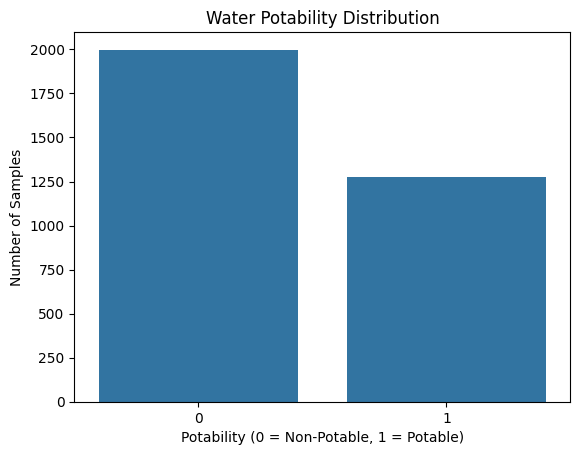

In [ ]:
sns.countplot(x="Potability", data=df)

plt.title("Water Potability Distribution")
plt.xlabel("Potability (0 = Non-Potable, 1 = Potable)")
plt.ylabel("Number of Samples")

plt.show()

DISTRIBUTION OF WATER QUALITY PARAMETERS

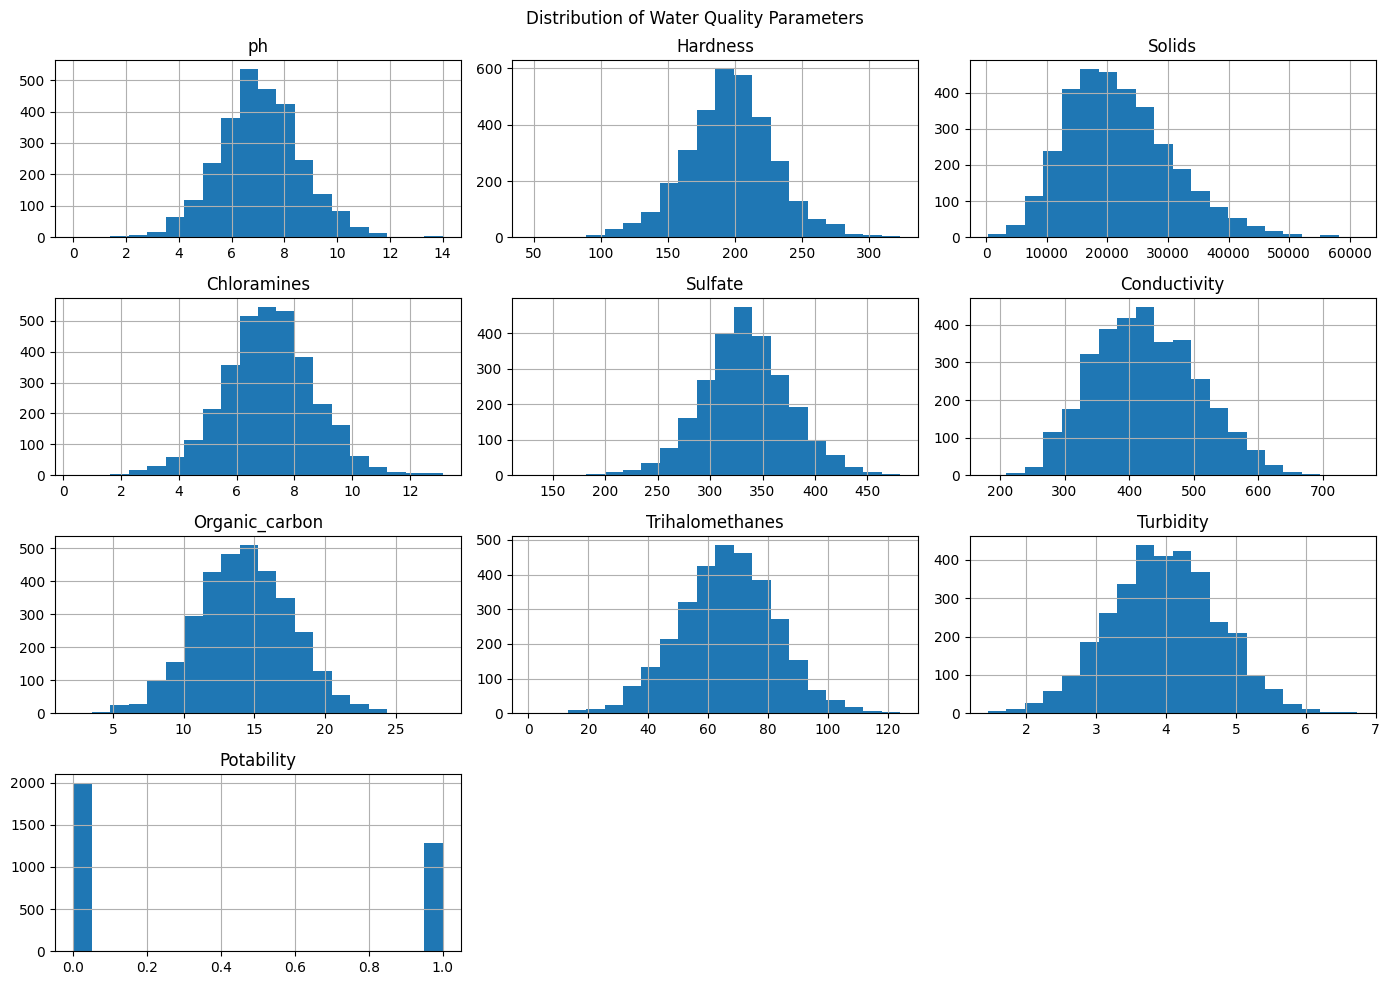

In [ ]:
df.hist(figsize=(14, 10), bins=20)

plt.suptitle("Distribution of Water Quality Parameters")

plt.tight_layout()
plt.show()

**DATA PREPROCESSING**

SEPARATING INPUT AND OUTPUT COLUMNS

In [ ]:
X = df.drop("Potability", axis=1)

y = df["Potability"]

print("Input Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features:
         ph    Hardness        Solids  Chloramines     Sulfate  Conductivity  \
0       NaN  204.890455  20791.318981     7.300212  368.516441    564.308654   
1  3.716080  129.422921  18630.057858     6.635246         NaN    592.885359   
2  8.099124  224.236259  19909.541732     9.275884         NaN    418.606213   
3  8.316766  214.373394  22018.417441     8.059332  356.886136    363.266516   
4  9.092223  181.101509  17978.986339     6.546600  310.135738    398.410813   

   Organic_carbon  Trihalomethanes  Turbidity  
0       10.379783        86.990970   2.963135  
1       15.180013        56.329076   4.500656  
2       16.868637        66.420093   3.055934  
3       18.436524       100.341674   4.628771  
4       11.558279        31.997993   4.075075  

Target Values:
0    0
1    0
2    0
3    0
4    0
Name: Potability, dtype: int64


DATASET SPLIT

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (2620, 9)
Testing Data: (656, 9)


PREPARE KNN PIPELINE

In [ ]:
knn_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


**APPLYING KNN ALGORITHM**

FINDING BEST K VALUE

In [ ]:
# Different K values to test
k_values = list(range(1, 32, 2))

# Parameters for testing
param_grid = {
    "knn__n_neighbors": k_values,
    "knn__weights": ["uniform", "distance"]
}

# 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid Search
grid_search = GridSearchCV(
    knn_pipeline,
    param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

# Train and compare models
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)

print("Best Cross-Validation F1 Score:",
      grid_search.best_score_)

Best Parameters: {'knn__n_neighbors': 5, 'knn__weights': 'distance'}
Best Cross-Validation F1 Score: 0.594442005292769


VISUALIZING K SELECTION RESULTS

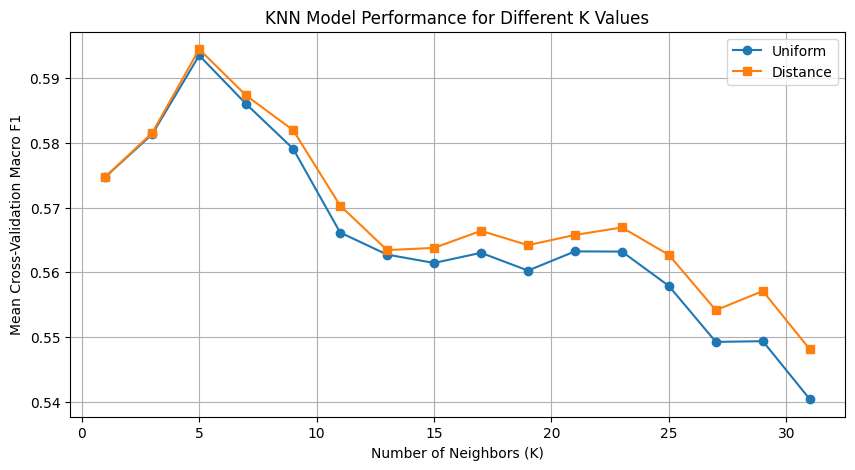

In [ ]:
results = pd.DataFrame(grid_search.cv_results_)

uniform_results = results[
    results["param_knn__weights"] == "uniform"
]

distance_results = results[
    results["param_knn__weights"] == "distance"
]

plt.figure(figsize=(10, 5))

plt.plot(
    uniform_results["param_knn__n_neighbors"].astype(int),
    uniform_results["mean_test_score"],
    marker="o",
    label="Uniform"
)

plt.plot(
    distance_results["param_knn__n_neighbors"].astype(int),
    distance_results["mean_test_score"],
    marker="s",
    label="Distance"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean Cross-Validation Macro F1")
plt.title("KNN Model Performance for Different K Values")

plt.legend()
plt.grid(True)

plt.show()

TRAINING THE FINAL MODEL

In [ ]:
best_model = grid_search.best_estimator_

print("Final KNN Model:")
print(best_model)

Final KNN Model:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('knn', KNeighborsClassifier(weights='distance'))])


TESTING THE MODEL

In [ ]:
y_pred = best_model.predict(X_test)

print("Actual Values:")
print(y_test.values[:10])

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
[1 0 0 0 0 0 0 0 1 1]

Predicted Values:
[0 0 0 0 0 0 0 0 0 0]


EVALUATING MODEL PERFORMANCE

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("Model Performance")

print("Accuracy:", round(accuracy * 100, 2), "%")

print("Precision:", round(precision, 3))

print("Recall:", round(recall, 3))

print("F1 Score:", round(f1, 3))

Model Performance
Accuracy: 61.43 %
Precision: 0.509
Recall: 0.32
F1 Score: 0.393


CONFUSION MATRIX

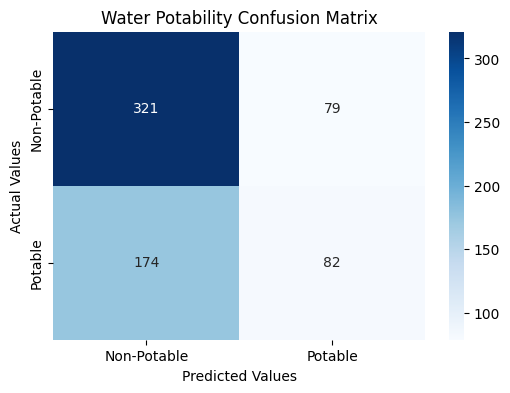

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Potable", "Potable"],
    yticklabels=["Non-Potable", "Potable"]
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.title("Water Potability Confusion Matrix")

plt.show()

DETAILED CLASSIFICATION REPORT

In [ ]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Potable", "Potable"],
    zero_division=0
))

              precision    recall  f1-score   support

 Non-Potable       0.65      0.80      0.72       400
     Potable       0.51      0.32      0.39       256

    accuracy                           0.61       656
   macro avg       0.58      0.56      0.56       656
weighted avg       0.59      0.61      0.59       656



**DEMONSTARTION OF NEW PREDICTION**

TESTING A SAMPLE RECORD

In [ ]:
sample = X_test.iloc[[0]]

prediction = best_model.predict(sample)

print("Water Sample Parameters:")
print(sample)

print("\nPrediction:")

if prediction[0] == 1:
    print("Potable (Class 1)")
else:
    print("Non-Potable (Class 0)")

Water Sample Parameters:
     ph    Hardness        Solids  Chloramines  Sulfate  Conductivity  \
664 NaN  188.743562  19037.462638     6.034236      NaN    388.065857   

     Organic_carbon  Trihalomethanes  Turbidity  
664       15.149068        78.499418   2.723651  

Prediction:
Non-Potable (Class 0)


In [ ]:
probability = best_model.predict_proba(sample)

print("Non-Potable Probability:",
      round(probability[0][0] * 100, 2), "%")

print("Potable Probability:",
      round(probability[0][1] * 100, 2), "%")

Non-Potable Probability: 77.83 %
Potable Probability: 22.17 %
